# 05 · Single-neuron computation: conjunction capacity vs abstraction

**Question 4.** *Single neurons can do many things (dendritic XOR, learning order relations, acting as
controllers). How are these abilities related to mixed selectivity vs disentangled representations?*

Hypothesis: **a single neuron faces the same trade-off as a population.**
* Dendritic nonlinearities give one neuron *conjunction capacity* (it can compute XOR-like, nonlinearly
  mixed functions — Poirazi et al. 2003; Gidon et al. 2020's dCaAP).
* Learning an **order relation** from adjacent pairs and generalising transitively requires an *abstract,
  linear, one-dimensional* code (a "value" axis) — a disentangled code at the level of synaptic weights.
* Nonlinear dendrites that buy capacity should cost abstraction (transitive generalisation), and where
  the nonlinearity sits (within a branch vs at the soma) decides whether branches are pure while the soma is mixed.

Sections: (1) Boolean-function capacity of neuron types, (2) transitive inference, (3) the trade-off plane,
(4) populations of dendritic neurons: branch-level vs soma-level selectivity.

In [1]:
import os, sys, json, time
import numpy as np
import torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))
from mixdis import data, models, metrics, dendrite, rnn
from mixdis.utils import save_json, load_json, set_threads

# FAST=1 -> tiny smoke-test run (minutes). Unset/0 -> full experiment.
FAST = os.environ.get("FAST", "0") == "1"
set_threads()
RES = os.path.abspath("../results"); os.makedirs(RES, exist_ok=True)
FIG = os.path.join(RES, "figures"); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
def savefig(name):
    plt.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight", dpi=200)
    plt.savefig(os.path.join(FIG, name + ".pdf"), bbox_inches="tight")
print("FAST mode:", FAST, "| torch", torch.__version__, "| threads", torch.get_num_threads())

FAST mode: False | torch 2.14.1 | threads 7


In [2]:
import itertools
NEURONS = {"point": dict(n_branches=1, branch_act="linear"),
           "2 ReLU branches": dict(n_branches=2, branch_act="relu"),
           "1 dCaAP branch": dict(n_branches=1, branch_act="dcaap"),
           "4 ReLU branches": dict(n_branches=4, branch_act="relu"),
           "4 sigmoid branches": dict(n_branches=4, branch_act="sigmoid")}
RESTARTS = 2 if FAST else 4

## 1. Capacity: how many of the 256 Boolean functions of 3 inputs can one neuron implement?

In [3]:
Xb = np.array(list(itertools.product([0, 1], repeat=3)), np.float32)
funcs = np.array(list(itertools.product([0, 1], repeat=8)), np.float32)
funcs = funcs[(funcs.sum(1) > 0) & (funcs.sum(1) < 8)]          # drop constants
cap = {}
Xs = torch.tensor(Xb * 2 - 1); Ft = torch.tensor(funcs.T)          # (8 inputs, n_funcs targets)
for nm, cfg in NEURONS.items():
    solved = np.zeros(len(funcs), bool)
    for r in range(RESTARTS):
        # one dendritic neuron per Boolean function, all trained in parallel (independent parameters)
        layer = dendrite.DendriticLayer(3, len(funcs), cfg["n_branches"], cfg["branch_act"], "linear", init_scale=1.0, seed=r)
        opt = torch.optim.Adam(layer.parameters(), lr=5e-2)
        for it in range(400 if FAST else 2000):
            _, _, s_in = layer(Xs, return_pre=True)
            loss = torch.nn.functional.binary_cross_entropy_with_logits(s_in, Ft)
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            _, _, s_in = layer(Xs, return_pre=True)
        solved |= ((s_in > 0).float() == Ft).all(0).numpy()
    cap[nm] = float(solved.mean())
    print(f"{nm:20s} implements {cap[nm]*100:.0f}% of non-constant Boolean functions of 3 inputs")

point                implements 40% of non-constant Boolean functions of 3 inputs
2 ReLU branches      implements 93% of non-constant Boolean functions of 3 inputs
1 dCaAP branch       implements 57% of non-constant Boolean functions of 3 inputs
4 ReLU branches      implements 100% of non-constant Boolean functions of 3 inputs
4 sigmoid branches   implements 98% of non-constant Boolean functions of 3 inputs


**Result.** Fraction of the 254 non-constant Boolean functions of 3 inputs implemented by one neuron: point neuron 40 % (= 102/254,
the number of linearly separable functions — a sanity check), 1 dCaAP branch 57 %, 2 ReLU branches 93 %, 4 sigmoid branches 98 %,
4 ReLU branches 100 %.

## 2. Transitive inference: learn A>B, B>C, … from adjacent pairs, test all pairs

point                acc by symbolic distance [1. 1. 1. 1. 1. 1.] | value-vs-rank R² 1.00
2 ReLU branches      acc by symbolic distance [0.93 0.71 0.62 0.93 1.   1.  ] | value-vs-rank R² 0.67
1 dCaAP branch       acc by symbolic distance [0.84 0.62 0.34 0.68 0.98 0.95] | value-vs-rank R² 0.35
4 ReLU branches      acc by symbolic distance [0.99 0.75 0.69 1.   1.   1.  ] | value-vs-rank R² 0.85
4 sigmoid branches   acc by symbolic distance [1. 1. 1. 1. 1. 1.] | value-vs-rank R² 0.99


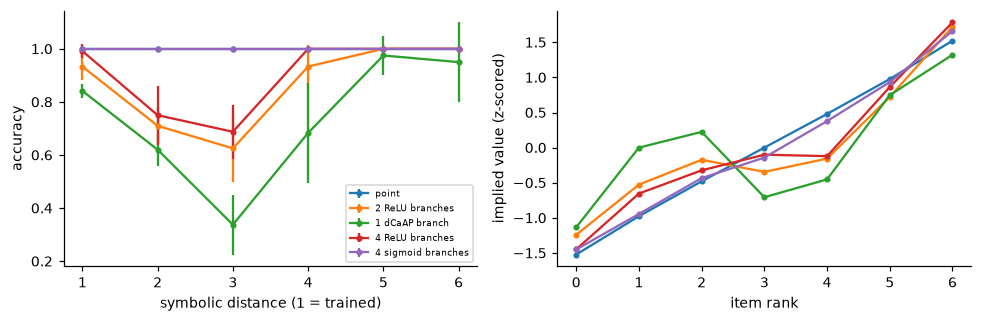

In [4]:
NI = 7
Xa, Ya, Da = dendrite.transitive_data(NI, "adjacent"); Xt, Yt, Dt = dendrite.transitive_data(NI, "all")
TI = {}
for nm, cfg in NEURONS.items():
    accs, vals = [], []
    for seed in range(3 if FAST else 10):
        n = dendrite.SingleNeuron(2 * NI, init_scale=0.1, seed=seed, **cfg)
        dendrite.train_classifier(n, Xa, Ya, steps=600 if FAST else 3000, lr=1e-2, w_l2=1e-3)
        with torch.no_grad():
            p = (n(torch.tensor(Xt))[0] > 0).float().numpy()
            # implied 'value' of item i: response to (i vs every other) averaged
            v = np.array([n(torch.tensor(Xt[(Xt[:, i] == 1)]))[0].mean().item() for i in range(NI)])
        accs.append([((p == Yt)[Dt == d]).mean() for d in range(1, NI)]); vals.append(v)
    TI[nm] = dict(acc=np.array(accs), val=np.array(vals))
    a = np.array(accs)
    lin = np.mean([np.corrcoef(v, np.arange(NI))[0, 1] ** 2 for v in vals])
    print(f"{nm:20s} acc by symbolic distance {np.round(a.mean(0), 2)} | value-vs-rank R² {lin:.2f}")
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
for nm in NEURONS:
    axs[0].errorbar(range(1, NI), TI[nm]["acc"].mean(0), TI[nm]["acc"].std(0), marker="o", ms=3, label=nm)
    v = TI[nm]["val"]; v = (v - v.mean(1, keepdims=True)) / (v.std(1, keepdims=True) + 1e-9)
    axs[1].plot(range(NI), v.mean(0), "-o", ms=3, label=nm)
axs[0].set_xlabel("symbolic distance (1 = trained)"); axs[0].set_ylabel("accuracy"); axs[0].legend(fontsize=6)
axs[1].set_xlabel("item rank"); axs[1].set_ylabel("implied value (z-scored)")
plt.tight_layout(); savefig("05_transitive_inference"); plt.show()

**Result (10 seeds).** Accuracy by symbolic distance (1 = trained pairs) and linearity of the implied value code:

| neuron | d = 1 | d = 2 | d = 3 | d = 4 | d = 5 | d = 6 | value-vs-rank R² |
|---|---|---|---|---|---|---|---|
| point | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 |
| 4 sigmoid branches | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 1.00 | 0.99 |
| 4 ReLU branches | 0.99 | 0.75 | 0.69 | 1.00 | 1.00 | 1.00 | 0.85 |
| 2 ReLU branches | 0.93 | 0.71 | 0.62 | 0.93 | 1.00 | 1.00 | 0.67 |
| 1 dCaAP branch | 0.84 | 0.62 | 0.34 | 0.68 | 0.98 | 0.95 | 0.35 |

A point neuron learns a perfect linear value axis and infers all transitive relations (Question 4: order relations are the single-neuron
analogue of a disentangled, abstract code). ReLU and dCaAP branches fail at intermediate distances, exactly where a linear value axis is
needed to generalise.

## 3. The single-neuron trade-off plane

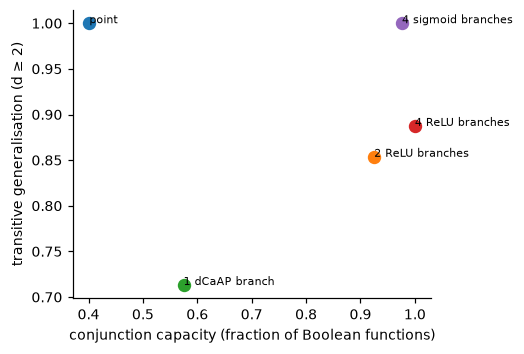

In [5]:
plt.figure(figsize=(4.2, 3.4))
for nm in NEURONS:
    gen = TI[nm]["acc"][:, 1:].mean()  # untrained distances >= 2
    plt.scatter(cap[nm], gen, s=60); plt.annotate(nm, (cap[nm], gen), fontsize=7)
plt.xlabel("conjunction capacity (fraction of Boolean functions)"); plt.ylabel("transitive generalisation (d ≥ 2)")
savefig("05_capacity_vs_abstraction"); plt.show()

**Result.** The trade-off depends on the **type** of dendritic nonlinearity, not on having dendrites: non-saturating (ReLU) and
non-monotonic (dCaAP) branches buy capacity at the cost of abstraction, but **saturating (sigmoid) branches obtain both** (98 % capacity
and perfect transitive inference), because near their linear range they preserve a monotonic value axis.

## 4. Populations of dendritic neurons: where does the mixing happen?
Multitask problem from notebook 03 (A × B × context, linear + nonlinear tasks), but inputs are one-hot factor
groups so that synapses can be **factor-segregated** (each branch samples one factor, as with clustered inputs)
or **intermixed** (each branch samples all inputs). We measure selectivity separately at the branch and the soma level.

point neurons (ReLU)           N=  2 acc 0.745 | soma NMS frac 0.00 | branch NMS frac 0.00 pure 0.00
point neurons (ReLU)           N=  4 acc 0.886 | soma NMS frac 0.50 | branch NMS frac 0.00 pure 0.25
point neurons (ReLU)           N=  8 acc 0.983 | soma NMS frac 0.75 | branch NMS frac 0.00 pure 0.00
point neurons (ReLU)           N= 16 acc 1.000 | soma NMS frac 0.88 | branch NMS frac 0.00 pure 0.06
point neurons (ReLU)           N= 32 acc 1.000 | soma NMS frac 0.78 | branch NMS frac 0.00 pure 0.06
dendritic, intermixed          N=  2 acc 0.795 | soma NMS frac 1.00 | branch NMS frac 0.50 pure 0.17
dendritic, intermixed          N=  4 acc 0.977 | soma NMS frac 0.75 | branch NMS frac 0.42 pure 0.00
dendritic, intermixed          N=  8 acc 1.000 | soma NMS frac 1.00 | branch NMS frac 0.75 pure 0.08
dendritic, intermixed          N= 16 acc 1.000 | soma NMS frac 1.00 | branch NMS frac 0.62 pure 0.04
dendritic, intermixed          N= 32 acc 1.000 | soma NMS frac 0.94 | branch NMS frac 0.76 

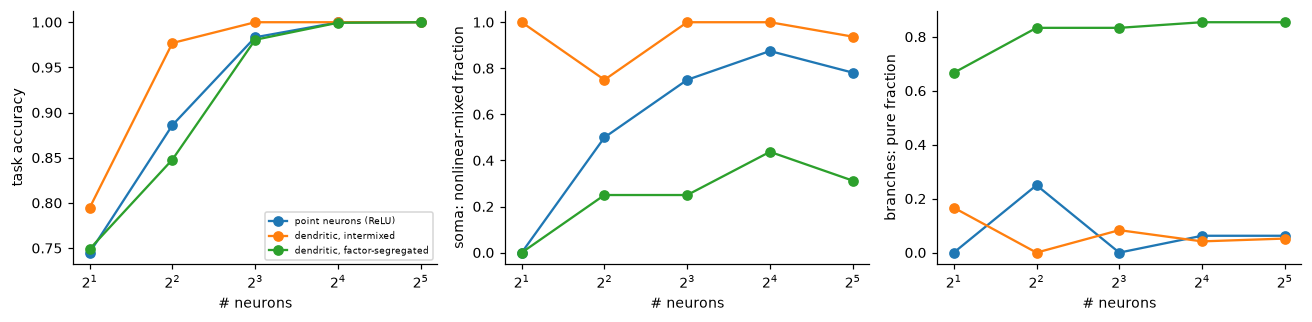

saved


In [6]:
lev = (3, 3, 2); conds = data.discrete_conditions(lev)
oh = np.concatenate([np.eye(l)[conds[:, k]] for k, l in enumerate(lev)], 1).astype(np.float32)
groups = [np.arange(0, 3), np.arange(3, 6), np.arange(6, 8)]
Y = np.c_[data.linear_tasks(conds, lev), data.random_dichotomy_tasks(conds, 4, seed=1, levels=lev)]
rng = np.random.default_rng(0)
X, Yt, ci = data.trials_from_conditions(oh, Y, 20 if FAST else 40, noise=0.2, rng=rng)
NSIZES = [4, 16] if FAST else [2, 4, 8, 16, 32]
VAR = {"point neurons (ReLU)": dict(n_branches=1, branch_act="linear", bg=None),
       "dendritic, intermixed": dict(n_branches=3, branch_act="relu", bg=None),
       "dendritic, factor-segregated": dict(n_branches=3, branch_act="relu", bg=[0, 1, 2])}
R4 = {}
for nm, cfg in VAR.items():
    for N in NSIZES:
        net = dendrite.DendriticNet(X.shape[1], N, Y.shape[1], n_branches=cfg["n_branches"], branch_act=cfg["branch_act"],
                                    groups=groups if cfg["bg"] else None, branch_groups=cfg["bg"], seed=0)
        models.train(net, X, Yt, "bce", steps=300 if FAST else 4000, act_l2=1e-3, w_l2=1e-5)
        with torch.no_grad():
            _, h, br = net(torch.tensor(X), return_branches=True)
        h, br = h.numpy(), br.numpy().reshape(len(X), -1)
        cs, ns, _ = metrics.selectivity_discrete(h, conds[ci]); cb, nb, _ = metrics.selectivity_discrete(br, conds[ci])
        R4[(nm, N)] = dict(acc=models.task_accuracy(net, X, Yt),
                           soma_nms_frac=metrics.class_fractions(cs)["nonlinear_mixed"], soma_nms=float(np.nanmean(ns)),
                           branch_nms_frac=metrics.class_fractions(cb)["nonlinear_mixed"], branch_nms=float(np.nanmean(nb)),
                           branch_pure=metrics.class_fractions(cb)["pure"], soma_pure=metrics.class_fractions(cs)["pure"])
        print(f"{nm:30s} N={N:3d} acc {R4[(nm,N)]['acc']:.3f} | soma NMS frac {R4[(nm,N)]['soma_nms_frac']:.2f} "
              f"| branch NMS frac {R4[(nm,N)]['branch_nms_frac']:.2f} pure {R4[(nm,N)]['branch_pure']:.2f}")
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
for nm in VAR:
    axs[0].plot(NSIZES, [R4[(nm, N)]["acc"] for N in NSIZES], "-o", label=nm)
    axs[1].plot(NSIZES, [R4[(nm, N)]["soma_nms_frac"] for N in NSIZES], "-o", label=nm)
    axs[2].plot(NSIZES, [R4[(nm, N)]["branch_pure"] for N in NSIZES], "-o", label=nm)
for ax, t in zip(axs, ["task accuracy", "soma: nonlinear-mixed fraction", "branches: pure fraction"]):
    ax.set_xscale("log", base=2); ax.set_xlabel("# neurons"); ax.set_ylabel(t)
axs[0].legend(fontsize=6); plt.tight_layout(); savefig("05_dendritic_populations"); plt.show()
save_json({"capacity": cap, "TI": {k: {"acc": v["acc"], "val": v["val"]} for k, v in TI.items()},
           "R4": {f"{k[0]}|{k[1]}": v for k, v in R4.items()}, "NSIZES": NSIZES},
          os.path.join(RES, "nb05_single_neurons.json")); print("saved")

**Result.** Where synapses are placed decides where mixing happens:

* Point neurons: soma nonlinear-mixed fraction rises with population size (0.00 with 2 neurons, 0.50 with 4, 0.78–0.88 with 16–32).
* Dendritic neurons with intermixed synapses: mixing happens **inside** branches (branch NMS 0.42–0.76) and at the soma (0.75–1.00);
  they solve the task with the fewest neurons (0.977 with 4 neurons vs 0.886 point, 0.848 segregated).
* Dendritic neurons with **factor-segregated** synapses: branches stay **pure** (83–85 % with ≥ 4 neurons) while the soma mixes moderately (0.25–0.44),
  and the population still solves the task with ≥ 16 neurons (≥ 0.999).

### Summary of notebook 05
* One neuron can be "mixed" (dendritic conjunctions) or "abstract" (a linear value axis for order relations); ReLU and dCaAP branches trade
  one for the other, saturating branches do not.
* Compartmentalised selectivity is a testable prediction: with clustered (factor-segregated) inputs, branch-level tuning should be pure
  while somatic output is mixed.